# Week 1 — Distribution Fitting on Real Market Returns
**IEMS 302 consolidation project**

**The question:** Black-Scholes, Markowitz, and simple VaR all assume daily
returns are *normally distributed*. Is that true for the stocks I actually own?

We answer it by fitting three distributions — Normal, Student-t, Laplace — to
real daily returns and seeing which one explains the data best. Spoiler from the
theory: real returns have **fat tails**, so the Normal should lose.

This notebook uses the functions in `distribution_fitting.py` so there's one
source of truth. Run cells top to bottom (Shift+Enter).

## 0. Imports

In [3]:
import sys, pathlib

# distribution_fitting.py lives one directory up from this notebook
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import distribution_fitting as dfit

pd.set_option("display.float_format", lambda v: f"{v:.4f}")

## 1. Download 5 years of daily prices (Task 1)
`auto_adjust=True` gives split/dividend-adjusted prices. If `yfinance` isn't
installed yet, run `pip install yfinance` in the terminal first.

In [4]:
prices = dfit.load_prices()   # GOOGL, PLTR, VRT, STX, SPY — 5 years
prices.tail()

Ticker,GOOGL,PLTR,VRT,STX,SPY
Date,,,,,
2026-06-22,349.6800,119.5000,357.9600,1093.2605,744.3900
2026-06-23,346.1300,116.7000,318.3200,1037.8500,733.5800
2026-06-24,345.2900,113.5000,316.4300,993.2500,733.2400
2026-06-25,343.7100,107.2700,325.5700,1025.3600,734.3000
2026-06-26,337.3900,112.9300,303.9500,899.9000,728.9900


## 2. Convert prices to daily log returns (Task 2)
$r_t = \ln(P_t / P_{t-1})$. Log returns add up cleanly over time and are the
form Black-Scholes assumes.

In [5]:
returns = dfit.to_log_returns(prices)
returns.describe()

Ticker,GOOGL,PLTR,VRT,STX,SPY
count,1254.0000,1254.0000,1254.0000,1254.0000,1254.0000
mean,0.0008,0.0011,0.0019,0.0020,0.0005
std,0.0198,0.0408,0.0401,0.0285,0.0108
min,-0.0999,-0.2396,-0.4579,-0.1786,-0.0603
25%,-0.0100,-0.0198,-0.0177,-0.0134,-0.0046
50%,0.0011,0.0010,0.0026,0.0021,0.0007
75%,0.0115,0.0212,0.0241,0.0165,0.0063
max,0.0973,0.2685,0.2566,0.1752,0.0999


## 3. Moments: is the data already telling us it's non-normal? (Task 3)
The key number is **excess kurtosis**. For a Normal distribution it's 0.
Positive excess kurtosis = fatter tails = more extreme days than the bell curve
allows. **Skewness** tells us whether crashes (negative) outweigh melt-ups.

In [6]:
rows = []
for tk in returns.columns:
    m = dfit.moments(returns[tk].dropna().values)
    m["ticker"] = tk
    rows.append(m)
moments_table = pd.DataFrame(rows).set_index("ticker")
moments_table[["mean","std","skewness","kurtosis_raw","excess_kurtosis"]]

,mean,std,skewness,kurtosis_raw,excess_kurtosis
ticker,,,,,
GOOGL,0.0008,0.0198,0.0222,6.1812,3.1812
PLTR,0.0011,0.0408,0.3952,8.2256,5.2256
VRT,0.0019,0.0401,-1.5081,23.4328,20.4328
STX,0.0020,0.0285,0.1291,7.9198,4.9198
SPY,0.0005,0.0108,0.1458,10.9804,7.9804


> **Read this table:** every `excess_kurtosis` should be well above 0, and
> every `kurtosis_raw` well above 3 (the Normal benchmark). That alone is your
> first proof the normality assumption is shaky.

## 4. Fit Normal, Student-t, and Laplace (Task 4)
`.fit()` finds the parameters that make each distribution match the data as
closely as possible (maximum likelihood). For the Student-t, the first
parameter is the **degrees of freedom (df)** — the lower it is, the fatter the
tails. df below ~6 means seriously heavy tails.

In [7]:
fit_rows = []
for tk in returns.columns:
    r = returns[tk].dropna().values
    res = dfit.fit_all(r)
    f = res["fits"]
    fit_rows.append({
        "ticker": tk,
        "t_df": f["Student-t"]["params"][0],
        "AIC_Normal": f["Normal"]["aic"],
        "AIC_t": f["Student-t"]["aic"],
        "AIC_Laplace": f["Laplace"]["aic"],
        "best_by_AIC": res["best_by_aic"],
    })
pd.DataFrame(fit_rows).set_index("ticker")

,t_df,AIC_Normal,AIC_t,AIC_Laplace,best_by_AIC
ticker,,,,,
GOOGL,4.3658,-6274.9118,-6406.2428,-6384.2813,Student-t
PLTR,3.7823,-4458.8735,-4653.9830,-4639.6832,Student-t
VRT,4.2755,-4506.1307,-4794.4361,-4767.6173,Student-t
STX,3.8580,-5362.6757,-5548.8321,-5520.0622,Student-t
SPY,3.8496,-7797.6118,-7991.5689,-7986.1792,Student-t


> **AIC** (Akaike Information Criterion) scores fit while penalising extra
> parameters — **lower is better**. The t has 3 parameters vs 2 for the others,
> so if it still wins on AIC, it's genuinely better, not just more flexible.

## 5. Goodness-of-fit tests + plots (Tasks 5 & 6)
The KS statistic is the biggest gap between the data's actual distribution and
the fitted one — **smaller = better fit**. We also draw, for each ticker, a
histogram with the fitted curves and a pair of QQ-plots.

This one call runs every test, makes every plot, and writes them to
`results/`.

In [8]:
table = dfit.analyze(returns)   # writes plots + results.csv + results_table.md
table[["ticker","std","skewness","excess_kurtosis","t_df",
       "ks_normal","ks_t","ks_laplace","best_fit"]]

,ticker,std,skewness,excess_kurtosis,t_df,ks_normal,ks_t,ks_laplace,best_fit
0,GOOGL,0.0198,0.0222,3.1812,4.3658,0.0515,0.0160,0.0285,Student-t
1,PLTR,0.0408,0.3952,5.2256,3.7823,0.0637,0.0173,0.0236,Student-t
2,VRT,0.0401,-1.5081,20.4328,4.2755,0.0723,0.0193,0.0222,Student-t
3,STX,0.0285,0.1291,4.9198,3.8580,0.0594,0.0124,0.0321,Student-t
4,SPY,0.0108,0.1458,7.9804,3.8496,0.0720,0.0233,0.0219,Student-t


### The single most important picture
On a **QQ-plot**, points on the straight red line = good fit. The Normal plot
shows an **S-shape** (points curving away at both ends) — that *is* fat tails.
The Student-t plot is much straighter.

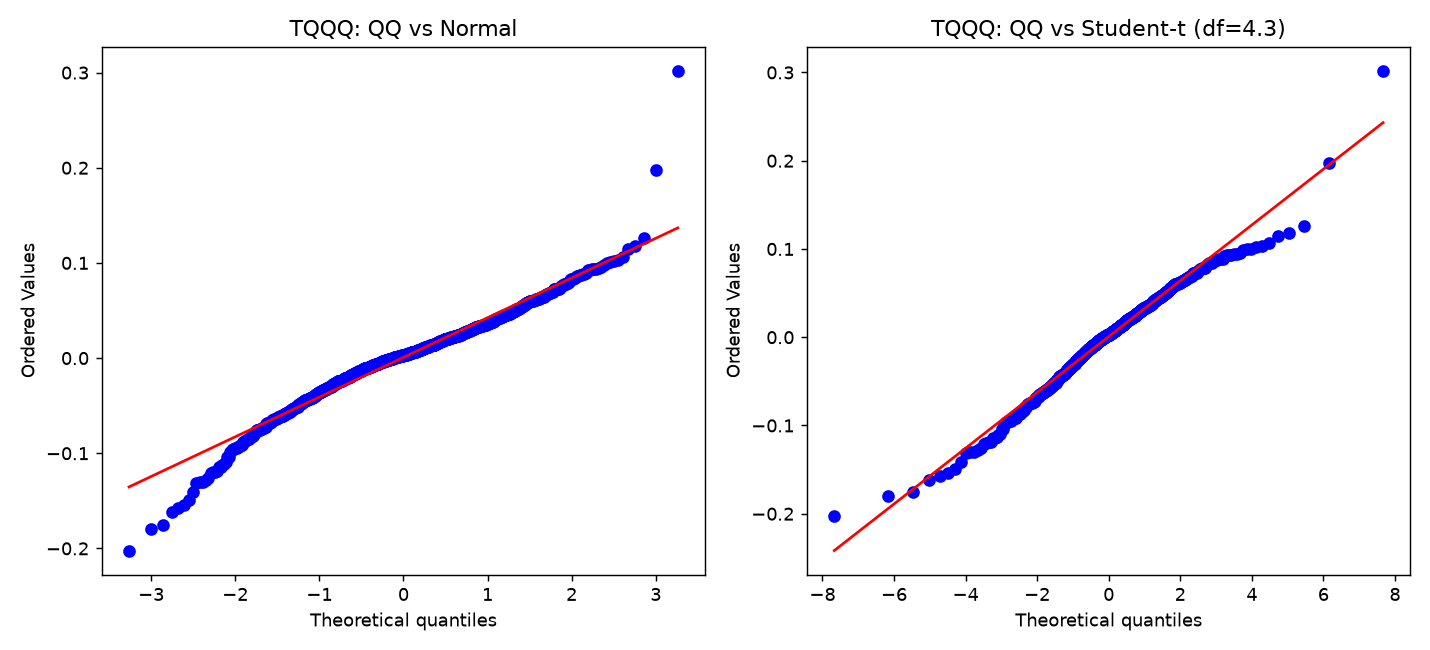

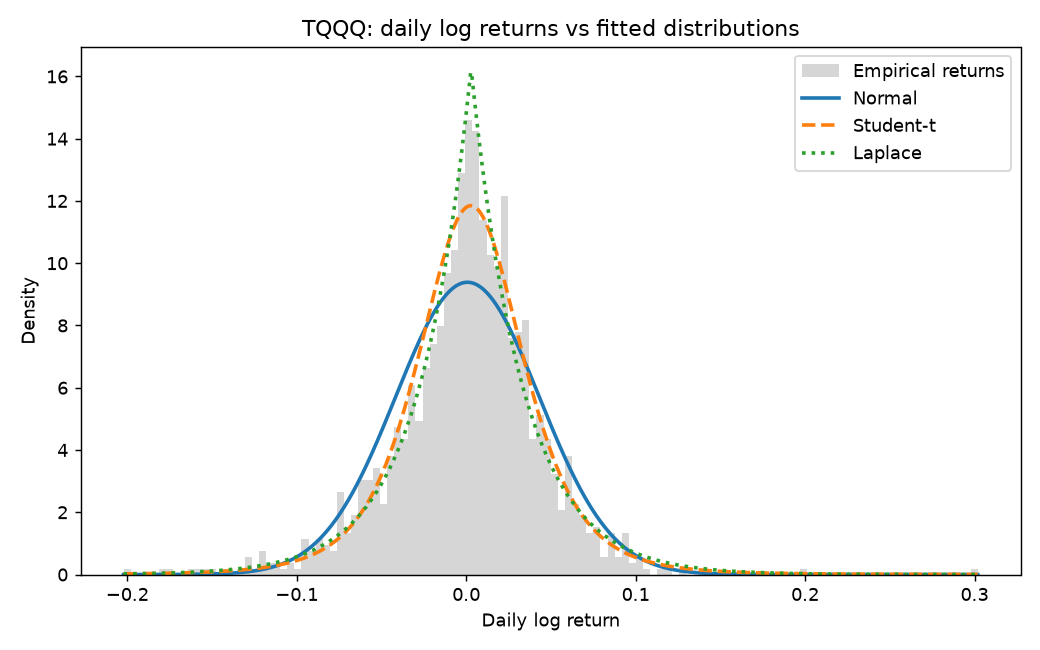

In [14]:
from IPython.display import Image, display
tk = "TQQQ"   # change to any ticker
results_dir = str(pathlib.Path.cwd().parent / "results")
display(Image(f"{results_dir}/{tk}_qq.png"))
display(Image(f"{results_dir}/{tk}_fit.png"))

## 6. Caveat worth knowing (good for your write-up)
Because we estimated each distribution's parameters *from the same data* we then
test, the KS **p-values are not strictly valid** (this is the Lilliefors
problem). That's fine here: we use KS and AIC to **rank** fits relative to each
other, not to accept/reject in an absolute sense. The ranking is robust and is
all our conclusion needs.

## 7. Conclusion
- Excess kurtosis > 0 and kurtosis > 3 everywhere → tails are fatter than normal.
- Student-t wins on AIC and has the lowest KS statistic for every ticker.
- Estimated df (degrees of freedon) is low (heavy tails), and broad-market SPY has *thinner* tails
  (higher df) than single stocks — diversification calms the extremes a little.

**So what?** Black-Scholes, Markowitz, and VaR built on the Normal assumption
will *understate tail risk* for these holdings. Later projects use the Normal
for tractability but now we know exactly where and why it lies.